In [1]:
import numpy as np
import pandas as pd

In [127]:
df = pd.read_csv('/content/placement.csv')

In [4]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [9]:
df.shape

(100, 4)

In [11]:
# Removing unwanted column
df = df.iloc[:,1:]

In [12]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [14]:
import matplotlib.pyplot as plt

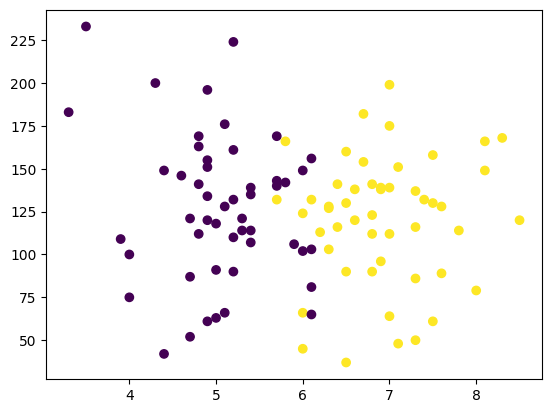

In [16]:
# Plotting Graph of given Dataset
plt.scatter(df['cgpa'],df['iq'],c=df['placement'])

In [128]:
# Assigning x = (cgpa,iq) & y = placements
x = df.iloc[:,:2]
y = df.iloc[:,-1]

In [101]:
x

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [102]:
y

,placement
0,1
1,0
2,0
3,1
4,0
...,...
95,0
96,0
97,1
98,1


In [103]:
y.shape

(100,)

In [104]:
# Splitting Data for testing & training
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.1)

In [105]:
x_train

,cgpa,iq
86,5.1,128.0
45,6.0,66.0
0,6.8,123.0
55,7.8,114.0
70,6.3,127.0
...,...,...
67,5.0,118.0
6,5.7,143.0
48,6.6,138.0
63,6.3,128.0


In [106]:
x_test

,cgpa,iq
34,4.8,163.0
96,4.4,42.0
93,6.8,112.0
10,6.0,45.0
39,4.6,146.0
36,5.7,140.0
5,7.1,48.0
35,6.8,90.0
81,5.4,107.0
82,6.5,37.0


In [107]:
y_train

,placement
86,0
45,1
0,1
55,1
70,1
...,...
67,0
6,0
48,1
63,1


In [108]:
y_test

,placement
34,0
96,0
93,1
10,1
39,0
36,0
5,1
35,1
81,0
82,1


In [130]:
# Scaling the values
from sklearn.preprocessing import StandardScaler

In [110]:
scaler = StandardScaler()

In [111]:
x_train = scaler.fit_transform(x_train)

In [112]:
x_train

array([[-7.87966301e-01,  2.72103428e-02],
       [-9.60934514e-03, -1.62315610e+00],
       [ 6.82263505e-01, -1.05883725e-01],
       [ 1.54710457e+00, -3.45453048e-01],
       [ 2.49842974e-01,  5.91529192e-04],
       [-7.01482195e-01,  1.33685597e-01],
       [-1.13390273e+00, -1.99581949e+00],
       [ 1.28765225e+00,  8.04479701e-02],
       [ 1.11468404e+00, -2.92215421e-01],
       [-1.13390273e+00, -1.59121353e-01],
       [-1.04741862e+00,  1.11858170e+00],
       [ 1.11468404e+00, -2.04905712e+00],
       [ 5.95779398e-01,  1.46462628e+00],
       [ 5.09295292e-01, -1.85740166e-01],
       [-9.60934514e-01,  7.45918311e-01],
       [-5.28513982e-01, -3.45453048e-01],
       [ 7.68747611e-02,  1.33685597e-01],
       [-1.04741862e+00,  3.73254920e-01],
       [ 6.82263505e-01,  3.73254920e-01],
       [ 3.36327080e-01,  3.73254920e-01],
       [-8.74450407e-01, -1.70301254e+00],
       [-2.69061664e-01,  1.33685597e-01],
       [-9.60934514e-01, -1.85740166e-01],
       [ 1.

In [113]:
x_test = scaler.transform(x_test)

In [114]:
x_test

array([[-1.04741862,  0.95886882],
       [-1.39335504, -2.26200763],
       [ 0.6822635 , -0.39869068],
       [-0.00960935, -2.18215119],
       [-1.22038683,  0.50634899],
       [-0.26906166,  0.34663611],
       [ 0.94171582, -2.10229475],
       [ 0.6822635 , -0.98430458],
       [-0.52851398, -0.53178474],
       [ 0.42281119, -2.3951017 ]])

In [129]:
# Importing Logistic Regression
from sklearn.linear_model import LogisticRegression

In [116]:
clf = LogisticRegression()

In [117]:
# Model Training
clf.fit(x_train,y_train)

LogisticRegression()

In [118]:
y_pred = clf.predict(x_test)

In [119]:
y_pred

array([0, 0, 1, 0, 0, 0, 1, 1, 0, 1])

In [120]:
y_test

,placement
34,0
96,0
93,1
10,1
39,0
36,0
5,1
35,1
81,0
82,1


In [131]:
# Evaluating Accuracy of the Model
from sklearn.metrics import accuracy_score

In [122]:
accuracy_score(y_test,y_pred)

0.9

In [123]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

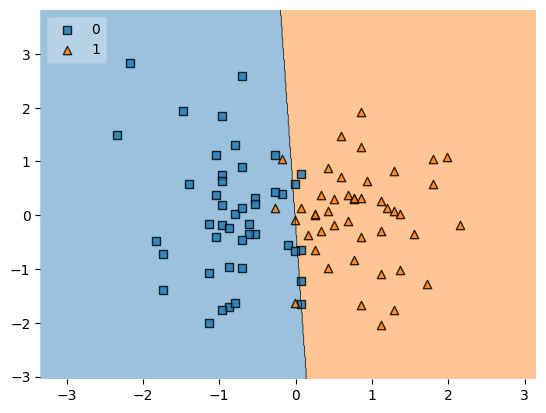

In [135]:
# Plotting Decision Regions
plot_decision_regions(x_train, y_train.values, clf=clf, legend=2)

In [125]:
import pickle

In [134]:
# Exporting the Model
pickle.dump(clf,open('model.pkl','wb'))